# Experiment No. 2 B (Group A)

**Aim:**  
Use the diabetes data set from UCI and Pima Indians Diabetes data set for performing the following:  
a. Univariate analysis: Frequency, Mean, Median, Mode, Variance, Standard Deviation, Skewness and Kurtosis  
b. Bivariate analysis: Linear and logistic regression modeling  
c. Multiple Regression analysis  
d. Also compare the results of the above analysis for the two data sets  

**Dataset Link:** `https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv`

**Objectives:**  
1. Load and inspect the Pima Indians Diabetes dataset using URL.
2. Perform comprehensive Univariate Analysis for all variables.
3. Perform Bivariate Analysis via Linear Regression and Logistic Regression modeling and extract coefficients.
4. Perform Multiple Regression analysis using Statsmodels OLS and display statistical summary.
5. Generate Correlation Matrix Heatmap and Scatterplot Matrix visualizations.
6. Compare analytical results and regression performance between Pima Indians and UCI Diabetes datasets.

In [9]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
from matplotlib import pyplot
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.linear_model import LinearRegression, LogisticRegression
import statsmodels.api as sm
from sklearn.datasets import load_diabetes

In [10]:
# Cell 2 - Load and Inspect Dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("diabetes.csv")

print("df.shape:", df.shape)
print("\ndf.head():")
display(df.head()) if 'display' in globals() else print(df.head())

print("\ndf.describe():")
display(df.describe()) if 'display' in globals() else print(df.describe())

df.shape: (768, 9)

df.head():
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

df.describe():
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.9726

In [11]:
# Cell 3 - Univariate Analysis: Frequency, Mean, Median, Mode, Variance, Standard Deviation, Skewness and Kurtosis
for column in df.columns:
    print(f"Column: {column}")
    print(f"Frequency:\n{df[column].value_counts()}\n")
    print(f"Mean: {df[column].mean()}")
    print(f"Median: {df[column].median()}")
    print(f"Mode:\n{df[column].mode()}")
    print(f"Variance: {df[column].var()}")
    print(f"Standard Deviation: {df[column].std()}")
    print(f"Skewness: {df[column].skew()}")
    print(f"Kurtosis: {df[column].kurt()}")
    print("------------------------ \n")

Column: Pregnancies
Frequency:
Pregnancies
1     135
0     111
2     103
3      75
4      68
5      57
6      50
7      45
8      38
9      28
10     24
11     11
13     10
12      9
14      2
15      1
17      1
Name: count, dtype: int64

Mean: 3.8450520833333335
Median: 3.0
Mode:
0    1
Name: Pregnancies, dtype: int64
Variance: 11.354056320621465
Standard Deviation: 3.3695780626988694
Skewness: 0.9016739791518588
Kurtosis: 0.15921977754746486
------------------------ 

Column: Glucose
Frequency:
Glucose
100    17
99     17
125    14
111    14
106    14
       ..
56      1
169     1
149     1
65      1
190     1
Name: count, Length: 136, dtype: int64

Mean: 120.89453125
Median: 117.0
Mode:
0     99
1    100
Name: Glucose, dtype: int64
Variance: 1022.2483142519557
Standard Deviation: 31.97261819513622
Skewness: 0.17375350179188992
Kurtosis: 0.6407798203735053
------------------------ 

Column: BloodPressure
Frequency:
BloodPressure
70     57
74     52
78     45
68     45
72     44
64  

In [12]:
# Cell 4 - Bivariate Analysis: Linear and Logistic Regression Modeling
# 1. Linear Regression
X_linear = df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']]
y_linear = df['Outcome']

model_linear = LinearRegression()
model_linear.fit(X_linear, y_linear)

print('Linear Regression Coefficients:')
for feature, coef in zip(X_linear.columns, model_linear.coef_):
    print(f'{feature}: {coef}')

# Make predictions
predictions_linear = model_linear.predict(X_linear)

# 2. Logistic Regression
X_logistic = df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']]
y_logistic = df['Outcome']

model_logistic = LogisticRegression(max_iter=1000)
model_logistic.fit(X_logistic, y_logistic)

print('\nLogistic Regression Coefficients:')
for feature, coef in zip(X_logistic.columns, model_logistic.coef_[0]):
    print(f'{feature}: {coef}')

# Make predictions
predictions_logistic = model_logistic.predict(X_logistic)

Linear Regression Coefficients:
Glucose: 0.005932504680360895
BloodPressure: -0.0022788371254208895
SkinThickness: 0.00016697889986788482
Insulin: -0.00020961695141379134
BMI: 0.013310837289280052
DiabetesPedigreeFunction: 0.1376781570786881
Age: 0.0058006843450717355

Logistic Regression Coefficients:
Glucose: 0.03454523153220714
BloodPressure: -0.012211613064915453
SkinThickness: 0.0010025941131288714
Insulin: -0.0013499129747817499
BMI: 0.08781260249268318
DiabetesPedigreeFunction: 0.8190841100471677
Age: 0.03269772511377604


In [13]:
# Cell 5 - Multiple Regression Analysis using Statsmodels OLS
# Split the dataset into independent variables (X) and dependent variable (y)
X = df.drop('Outcome', axis=1) # Independent variables
y = df['Outcome']              # Dependent variable

# Add a constant column to the independent variables
X = sm.add_constant(X)

# Fit the multiple regression model
model = sm.OLS(y, X)
results = model.fit()

# Print the regression results
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                Outcome   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     41.29
Date:                Wed, 07 Oct 2026   Prob (F-statistic):           7.36e-55
Time:                        23:52:47   Log-Likelihood:                -381.91
No. Observations:                 768   AIC:                             781.8
Df Residuals:                     759   BIC:                             823.6
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

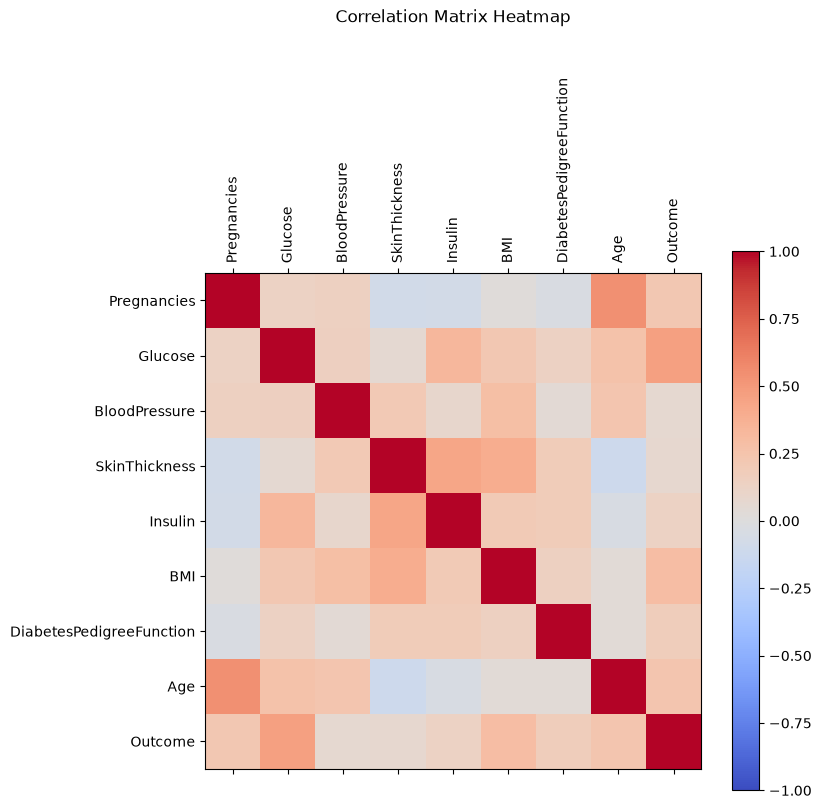

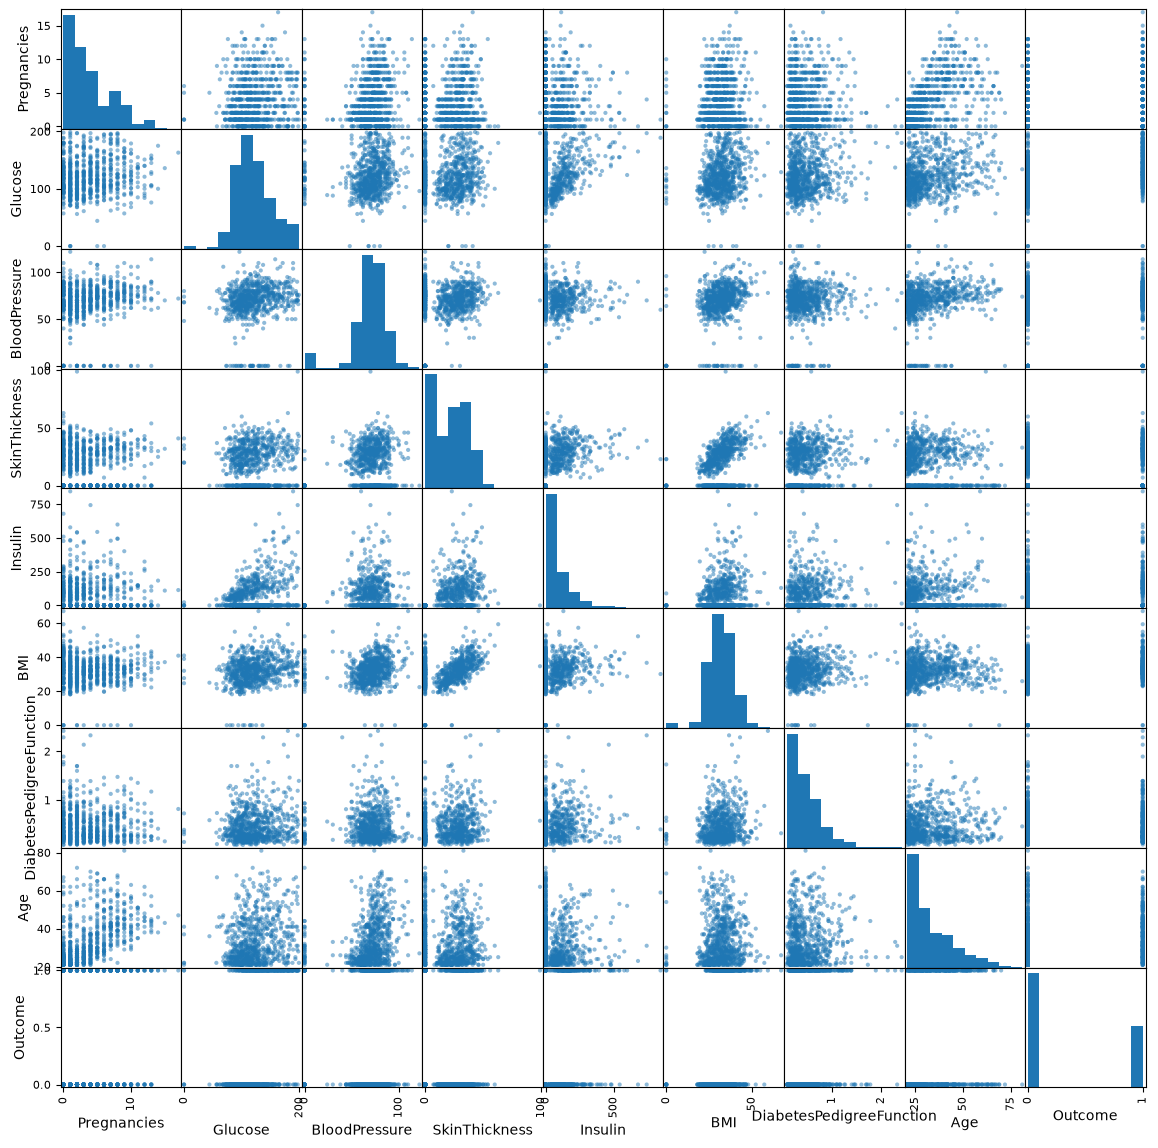

In [14]:
# Cell 6 - Visualizations: Correlation Heatmap and Scatterplot Matrix
# Correlation Matrix Heatmap
corr = df.corr()
fig = pyplot.figure(figsize=(8, 7))
ax = fig.add_subplot(111)
cax = ax.matshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
fig.colorbar(cax)
ticks = np.arange(0, 9, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
names = df.columns
# Rotate x-tick labels by 90 degrees
ax.set_xticklabels(names, rotation=90)
ax.set_yticklabels(names)
pyplot.title("Correlation Matrix Heatmap", pad=40)
pyplot.show()

# Scatterplot Matrix
pyplot.rcParams['figure.figsize'] = [14, 14]
scatter_matrix(df)
pyplot.show()

In [15]:
# Cell 7 - Comparative Analysis of Two Datasets (Pima Indians vs UCI Diabetes)
uci_data = load_diabetes(as_frame=True)
uci_df = uci_data.frame

# Fit multiple regression on UCI dataset
X_uci = sm.add_constant(uci_df.drop('target', axis=1))
y_uci = uci_df['target']
uci_results = sm.OLS(y_uci, X_uci).fit()

# Comparative Table
comparison_df = pd.DataFrame({
    'Analysis Metric': [
        'Sample Count (Rows)',
        'Feature Count (Columns)',
        'Target Variable Name',
        'Target Variable Type',
        'OLS R-squared',
        'OLS Adj. R-squared',
        'OLS F-statistic',
        'Prob (F-statistic)'
    ],
    'Pima Indians Dataset': [
        len(df),
        df.shape[1] - 1,
        'Outcome',
        'Binary (0 / 1)',
        round(results.rsquared, 3),
        round(results.rsquared_adj, 3),
        round(results.fvalue, 2),
        f"{results.f_pvalue:.2e}"
    ],
    'UCI Diabetes Dataset': [
        len(uci_df),
        uci_df.shape[1] - 1,
        'target',
        'Continuous (Disease Progression)',
        round(uci_results.rsquared, 3),
        round(uci_results.rsquared_adj, 3),
        round(uci_results.fvalue, 2),
        f"{uci_results.f_pvalue:.2e}"
    ]
})

print("--- Comparison Between Pima Indians & UCI Diabetes Datasets ---")
display(comparison_df) if 'display' in globals() else print(comparison_df.to_string())

--- Comparison Between Pima Indians & UCI Diabetes Datasets ---
           Analysis Metric Pima Indians Dataset              UCI Diabetes Dataset
0      Sample Count (Rows)                  768                               442
1  Feature Count (Columns)                    8                                10
2     Target Variable Name              Outcome                            target
3     Target Variable Type       Binary (0 / 1)  Continuous (Disease Progression)
4            OLS R-squared                0.303                             0.518
5       OLS Adj. R-squared                0.296                             0.507
6          OLS F-statistic                41.29                             46.27
7       Prob (F-statistic)             7.36e-55                          3.83e-62
